# Customer Support Analysis - EDA (RQ1)

**RQ1: Do posting time and wording affect how fast support teams respond?**

- **Part 1 - Posting time:** do customers who post in the morning, afternoon, evening or at night wait different amounts of time? What about weekdays?
- **Part 2 - Wording:** do polite tweets get faster replies than rude or angry ones?

Methods: medians by group, regular-expression word lists (checked by hand), VADER sentiment as a second method, and a regression that controls for hour and date.

We use `cases.pkl` from `cleaning2.ipynb`. Each row is one customer tweet paired with the first reply from AppleSupport or AmazonHelp, and `response_minutes` is how long the customer waited.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Load the cases built in cleaning2.ipynb (one customer tweet + first brand reply per row)
cases = pd.read_pickle("../data/cases.pkl")
print("Data Shape:", cases.shape)
cases.head()

Data Shape: (209868, 10)


,case_id,brand,customer_id,customer_text,created_at,is_first_tweet,reply_tweet_id,reply_text,reply_at,response_minutes
0,193661,AppleSupport,161535,@AppleSupport Yes I’m able to open safari but ...,2017-10-04 00:03:07+00:00,False,193660,@161535 Understood! Can you tell us the versio...,2017-10-04 00:59:51+00:00,56.733333
1,1286995,AmazonHelp,421025,"@AmazonHelp I can't explain in 140 c, that's w...",2017-10-04 00:04:13+00:00,False,1286994,@421025 You can send us a direct message if yo...,2017-10-04 00:12:31+00:00,8.300000
2,243032,AppleSupport,173714,Apple Podcast is not played continuously on #i...,2017-10-04 00:07:40+00:00,True,243030,@173714 Let's see if we can keep your podcasts...,2017-10-04 00:36:31+00:00,28.850000
3,387506,AppleSupport,207722,@AppleSupport I did that yesterday.,2017-10-04 00:15:29+00:00,False,387504,"@207722 Which iPhone do you have, and what's t...",2017-10-04 00:37:54+00:00,22.416667
4,1286993,AmazonHelp,421025,"@AmazonHelp I found the email, never mind.",2017-10-04 00:24:40+00:00,False,1286992,@421025 No problem! Anytime you need assistanc...,2017-10-04 00:33:30+00:00,8.833333


## Part 1: Posting Time

### 1. Convert to Local Time

`created_at` is stored in UTC. We convert it to US Eastern Time so that "morning" and "night" match local hours. We do not know each customer's real time zone, so we assume most customers are in the US.

In [2]:
# created_at is stored in UTC; convert to US Eastern Time so "morning" and "night" match local hours
# tz_convert also handles the DST change on Nov 5, 2017 automatically
cases["local_time"] = cases["created_at"].dt.tz_convert("America/New_York")

cases["hour"] = cases["local_time"].dt.hour            # hour of day, 0-23
cases["weekday"] = cases["local_time"].dt.day_name()   # Monday, Tuesday, ...

# Check the new columns
cases[["created_at", "local_time", "hour", "weekday", "response_minutes"]].head()

,created_at,local_time,hour,weekday,response_minutes
0,2017-10-04 00:03:07+00:00,2017-10-03 20:03:07-04:00,20,Tuesday,56.733333
1,2017-10-04 00:04:13+00:00,2017-10-03 20:04:13-04:00,20,Tuesday,8.300000
2,2017-10-04 00:07:40+00:00,2017-10-03 20:07:40-04:00,20,Tuesday,28.850000
3,2017-10-04 00:15:29+00:00,2017-10-03 20:15:29-04:00,20,Tuesday,22.416667
4,2017-10-04 00:24:40+00:00,2017-10-03 20:24:40-04:00,20,Tuesday,8.833333


### 2. Response Time by Hour

We use the **median** response time because a few very long waits would pull the mean up. The y-axis uses a log scale so both brands fit on one chart.

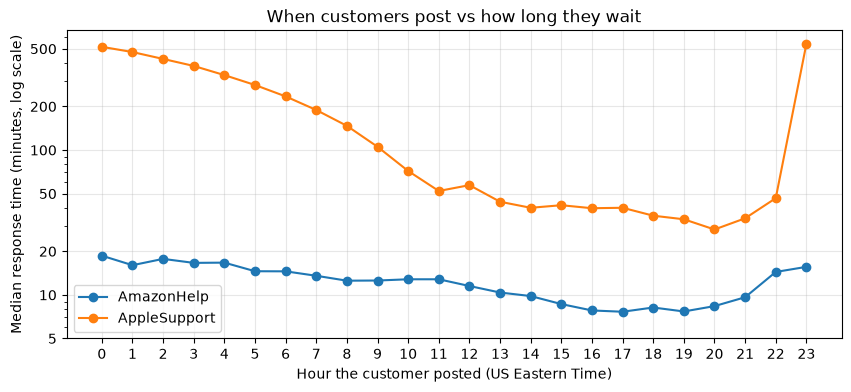

In [3]:
# Median response time for each (hour, brand) pair; median is robust to very long waits
hourly = cases.groupby(["hour", "brand"])["response_minutes"].median().unstack()

plt.figure(figsize=(10, 4))
for brand in hourly.columns:
    plt.plot(hourly.index, hourly[brand], marker="o", label=brand)
plt.yscale("log")   # log scale so both brands fit on one chart
plt.yticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])  # readable tick labels
plt.xticks(range(24))
plt.xlabel("Hour the customer posted (US Eastern Time)")
plt.ylabel("Median response time (minutes, log scale)")
plt.title("When customers post vs how long they wait")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3. Response Time by Time of Day

We group the 24 hours into four buckets: Morning (6-12), Afternoon (12-18), Evening (18-24) and Night (0-6).

In [4]:
def time_of_day(h):
    """Map an hour (0-23) to one of four time-of-day buckets."""
    if 6 <= h < 12:
        return "Morning (6-12)"
    elif 12 <= h < 18:
        return "Afternoon (12-18)"
    elif 18 <= h < 24:
        return "Evening (18-24)"
    else:
        return "Night (0-6)"

cases["time_of_day"] = cases["hour"].apply(time_of_day)
time_order = ["Morning (6-12)", "Afternoon (12-18)", "Evening (18-24)", "Night (0-6)"]

# Number of cases, median and mean wait for each brand and time bucket, in chronological order
time_summary = cases.groupby(["brand", "time_of_day"])["response_minutes"].agg(["count", "median", "mean"]).round(1)
time_summary.reindex(time_order, level="time_of_day")

count  median   mean
brand        time_of_day                            
AmazonHelp   Morning (6-12)     34406    13.1   18.3
             Afternoon (12-18)  30798     9.3   15.7
             Evening (18-24)    19860    10.1   16.5
             Night (0-6)        26466    16.5   23.4
AppleSupport Morning (6-12)     23034   118.0  131.9
             Afternoon (12-18)  35395    44.2   69.6
             Evening (18-24)    26969    41.6  125.1
             Night (0-6)        12940   436.9  428.8

### 4. Response Time by Weekday

In [5]:
# Median response time by weekday, in calendar order
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
cases.groupby(["weekday", "brand"])["response_minutes"].median().unstack().reindex(days).round(1)

brand,AmazonHelp,AppleSupport
weekday,,
Monday,13.4,48.0
Tuesday,12.4,41.3
Wednesday,11.7,40.2
Thursday,11.5,65.1
Friday,11.3,159.3
Saturday,12.1,168.1
Sunday,12.7,95.7


Apple is much slower from Thursday to Saturday. The iOS 11.1 keyboard bug (Oct 31 - Nov 9, 2017) made Apple slow for about ten days, so we check whether the weekday pattern is only caused by the bug.

In [6]:
# Check whether Apple's weekday pattern is driven by the iOS 11.1 bug period (Oct 31 - Nov 9, 2017)
apple = cases[cases["brand"] == "AppleSupport"]
in_bug = (apple["local_time"] >= "2017-10-31") & (apple["local_time"] < "2017-11-10")

pd.DataFrame({
    "All days": apple.groupby("weekday")["response_minutes"].median(),
    "Without bug period": apple[~in_bug].groupby("weekday")["response_minutes"].median(),
}).reindex(days).round(1)

,All days,Without bug period
weekday,,
Monday,48.0,24.4
Tuesday,41.3,28.8
Wednesday,40.2,36.1
Thursday,65.1,54.3
Friday,159.3,113.3
Saturday,168.1,117.5
Sunday,95.7,52.9


### Findings: Posting Time

- **AmazonHelp replies fast at every hour.** The median wait stays between about 8 and 19 minutes all day. Night posts (0-6) wait a little longer (16.5 min) than afternoon posts (9.3 min), but the gap is small. Amazon seems to staff support around the clock.
- **AppleSupport depends strongly on posting time.** Afternoon and evening posts wait about 42-44 minutes (median), but night posts wait about 437 minutes (over 7 hours), roughly **10 times longer**.
- The Apple curve jumps at **23:00 ET** and slowly falls until about 11:00. This suggests Apple's support team mostly stops replying late at night, so these tweets wait until the next morning.
- By weekday, Amazon is flat (11-13 min). Apple is slower from Thursday to Saturday (65-168 min) than from Monday to Wednesday (40-48 min). Part of this comes from the iOS 11.1 bug period, which made Apple slower overall. But even after removing those days, Friday and Saturday are still much slower (about 115 min vs 24-36 min), so the weekly pattern is not only caused by the bug.
- The data covers only about 9 weeks, so each weekday has only about 9 days. One very busy day can move a weekday's median a lot.

**Limitation:** we do not know each customer's real time zone, so we use US Eastern Time for everyone.

## Part 2: Wording

### 1. Clean the Text

We remove @mentions and links, because they are not the customer's own words and could confuse the word matching.

In [7]:
# Remove @mentions and links so they don't affect word matching
text = (cases["customer_text"]
        .str.replace(r"@\w+", "", regex=True)
        .str.replace(r"http\S+", "", regex=True))

# Compare one tweet before and after cleaning
print("Before:", cases["customer_text"].iloc[0])
print("After: ", text.iloc[0])

Before: @AppleSupport Yes I’m able to open safari but the problem is that it’s gets faded everytime not only safari all apps.
After:   Yes I’m able to open safari but the problem is that it’s gets faded everytime not only safari all apps.


### 2. Polite and Rude Word Lists

We flag polite and rude tweets with **regular expressions**. The word lists were built in rounds: we started from common words, then read random tweets that were *not* flagged and added the polite or rude words we had missed (for example *could you*, *hello*, *rubbish*, *scam*).

Pattern notes:
- `\b` is a word boundary, so `hate` does not match "whatever" or "hateful".
- `\w*` allows extra letters, so `\w*fuck\w*` matches "fucking" and "motherfucker".
- `thank(?:s|you|u)?` matches "thank", "thanks", "thankyou", "thanku" but **not** "Thanksgiving".

In [8]:
# Polite words: requests, thanks, apologies and greetings
polite_words = [
    "please", "pls", "plz", r"thank(?:s|you|u)?", "thx", "ty", r"appreciate\w*", "grateful",
    "kindly", "sorry", "excuse me", "could you", "would you", "regards", "dear", "hi", "hello",
    r"good (?:morning|afternoon|evening)",
]

# Rude words: swearing, insults and strong angry judgments
rude_words = [
    r"\w*fuck\w*", r"fuk\w*", r"\w*shit\w*", r"damn\w*", r"goddam\w*", "wtf", r"crap\w*", "hell",
    "ass", r"asshole\w*", "pissed", r"screw(?:ed|s)?", "stupid", r"idiot\w*", "dumb", "ridiculous",
    "worst", "terrible", "awful", "horrible", "useless", "pathetic", "rubbish", "garbage", "trash",
    "joke", "hate", r"sucks?", "annoying", "unacceptable", "disgusting", "incompetent", "clueless",
    "lame", r"scam\w*", r"cheat\w*", r"fraud\w*", r"liars?",
]

# Join each list into one pattern: \b(?:word1|word2|...)\b
polite_pattern = r"\b(?:" + "|".join(polite_words) + r")\b"
rude_pattern = r"\b(?:" + "|".join(rude_words) + r")\b"

cases["is_polite"] = text.str.contains(polite_pattern, case=False, regex=True)
cases["is_rude"] = text.str.contains(rude_pattern, case=False, regex=True)
cases["has_exclaim"] = text.str.contains(r"!{2,}", regex=True)   # two or more "!" in a row

### 3. Shouting (All Caps)

A word in capital letters can mean shouting, but many all-caps words are just brand names or acronyms. We list the most common all-caps words to see which ones are not shouting.

In [9]:
# Most common all-caps words (4+ letters)
text.str.findall(r"\b[A-Z]{4,}\b").explode().value_counts().head(30)

customer_text
THIS       1016
ASAP        905
USPS        705
AMZL        599
HELP        597
PLEASE      513
ORDER       456
PHONE       421
SHIT        379
AMAZON      327
WHAT        326
YOUR        307
STILL       293
WITH        254
FUCKING     233
UPDATE      222
FUCK        222
HAVE        216
THAT        216
PRIME       204
AGAIN       199
NEVER       194
JUST        182
NEED        158
EVERY       156
TIME        154
APPLE       154
IPHONE      142
STOP        141
LETTER      135
Name: count, dtype: int64

Words such as USPS, AMZL (Amazon Logistics), ASAP and IPHONE are names or acronyms, not shouting. We exclude them, and we count a tweet as **shouting** only if it has **at least two** other all-caps words. One capital word may just be emphasis; several in a row read as shouting.

In [10]:
# All-caps words that are brand names or acronyms, not shouting
not_shouting = {
    "ASAP", "USPS", "AMZL", "AMZN", "AMAZON", "APPLE", "IPHONE", "IPAD", "IPOD", "IMAC", "MACBOOK",
    "ICLOUD", "ITUNES", "PRIME", "KINDLE", "ALEXA", "ECHO", "FEDEX", "HDMI", "WIFI",
}

def is_shouting(s):
    """True if the tweet has at least two all-caps words that are not names or acronyms."""
    caps_words = re.findall(r"\b[A-Z]{4,}\b", s)
    caps_words = [w for w in caps_words if w not in not_shouting]
    return len(caps_words) >= 2

cases["is_shouting"] = text.apply(is_shouting)

# Share of tweets with each feature
cases[["is_polite", "is_rude", "has_exclaim", "is_shouting"]].mean().round(3)

is_polite      0.179
is_rude        0.151
has_exclaim    0.037
is_shouting    0.022
dtype: float64

### 4. Tone Groups

A tweet can contain both polite and rude words (e.g. *"please fix this shit"*). We put each tweet into one of four groups:

- **Polite:** polite words, no rude words
- **Rude:** rude words, no polite words
- **Mixed:** both
- **Neutral:** neither

In [11]:
def tone_group(polite, rude):
    """Combine the polite and rude flags into one tone group."""
    if polite and rude:
        return "Mixed"
    elif polite:
        return "Polite"
    elif rude:
        return "Rude"
    else:
        return "Neutral"

cases["tone"] = [tone_group(p, r) for p, r in zip(cases["is_polite"], cases["is_rude"])]
tone_order = ["Polite", "Neutral", "Mixed", "Rude"]

cases["tone"].value_counts(normalize=True).reindex(tone_order).round(3)

tone
Polite     0.160
Neutral    0.689
Mixed      0.018
Rude       0.132
Name: proportion, dtype: float64

### 5. Manual Check of the Labels

Regular expressions match words, not meaning. To measure how often the labels are right, we drew **50 random tweets flagged polite and 50 flagged rude** and read each one by hand. A label is counted as correct if the tweet is really polite (or really rude/angry). The labels are saved in `rq1_manual_check.csv`.

The sample was drawn with:
```python
cases.loc[cases["is_polite"]].sample(50, random_state=1007)
cases.loc[cases["is_rude"]].sample(50, random_state=1007)
```

In [12]:
# Load the hand labels and attach the tweet text and current flags
check = pd.read_csv("rq1_manual_check.csv")
check = check.merge(cases[["case_id", "customer_text", "is_polite", "is_rude", "tone"]], on="case_id")

# Keep tweets still flagged by the current patterns (one "Thanksgiving" tweet was fixed after this check)
still_flagged = np.where(check["flag"] == "is_polite", check["is_polite"], check["is_rude"])
check = check[still_flagged]

print("Share of labels that are correct:")
print(check.groupby("flag")["correct"].agg(["count", "mean"]).round(2))

Share of labels that are correct:
           count  mean
flag                  
is_polite     49  0.69
is_rude       50  0.96


In [13]:
# Most polite-label errors are sarcastic "thanks"; do the tone groups help?
print("Correct rate for the 'Polite' tone group (polite words, no rude words):")
polite_check = check[(check["flag"] == "is_polite") & (check["tone"] == "Polite")]
print(round(polite_check["correct"].mean(), 2), f"({len(polite_check)} tweets)")

print("\nExamples of wrong polite labels:")
for _, row in check[(check["flag"] == "is_polite") & (check["correct"] == 0)].head(5).iterrows():
    print(f"- [{row['note']}] {row['customer_text'][:120]}")

Correct rate for the 'Polite' tone group (polite words, no rude words):
0.77 (43 tweets)

Examples of wrong polite labels:
- [sarcastic thanks] @115830 thanks for ruining the Christmas presents I ordered for family and not sending them in an amazon box and just wh
- [sarcastic thanks] Thanks @115858 for deleting all my numbers files from all my devices and the cloud with the latest update 🤬 https://t.co
- [sarcastic thanks, swearing] @AppleSupport this new update is bullshit!!! Thanks for fucking up my phone! AGAIN!!!
- [angry, says hate] hate. hate. hate ios 11. @AppleSupport MY DANG BATTERY DIES FASTER. please fix it smh.
- [sarcastic thanks for nothing] Thanks for nothing @115821 you guys didn’t deliver today due to amazon locker being filled. Called cust service and nobo


### 6. Response Time by Wording

In [14]:
# Median wait for each tone group
tone_table = cases.groupby(["brand", "tone"])["response_minutes"].agg(["count", "median"]).round(1)
tone_table.reindex(tone_order, level="tone")

count  median
brand        tone                  
AmazonHelp   Polite   18845    12.5
             Neutral  80435    11.8
             Mixed     1226    13.2
             Rude     11024    12.6
AppleSupport Polite   14820    75.4
             Neutral  64163    66.6
             Mixed     2653    95.4
             Rude     16702    94.3

In [15]:
# For "!!" and shouting, compare the median wait of tweets with vs without the feature
rows = []
for f in ["has_exclaim", "is_shouting"]:
    medians = cases.groupby(["brand", f])["response_minutes"].median().unstack()
    for brand in medians.index:
        rows.append({"feature": f, "brand": brand,
                     "without": medians.loc[brand, False], "with": medians.loc[brand, True]})

style = pd.DataFrame(rows)
style["difference"] = style["with"] - style["without"]   # positive = waits longer
style.round(1)

,feature,brand,without,with,difference
0,has_exclaim,AmazonHelp,12.0,11.4,-0.6
1,has_exclaim,AppleSupport,71.2,91.0,19.8
2,is_shouting,AmazonHelp,12.0,11.8,-0.3
3,is_shouting,AppleSupport,71.4,94.8,23.4


### 7. Sentiment with VADER

Word lists cannot read context: *"not terrible"* is positive, but our rude pattern flags it, and sarcasm fools the polite list. As a second method we use **VADER**, a sentiment tool built for social media. It handles negation, capital letters and "!!", and gives each tweet a score from -1 (most negative) to +1 (most positive).

VADER measures **sentiment**, not **politeness**. For example, *"sorry to bother you"* is polite but gets a negative score because of "sorry". So we use it as a check on the rude/negative side, not as a replacement for the polite list.

In [16]:
analyzer = SentimentIntensityAnalyzer()

# A few examples
for s in ["This is not terrible", "iOS 11 sucks!!", "sorry to bother you", "Thanks for nothing"]:
    print(f"{s:25} {analyzer.polarity_scores(s)['compound']:+.2f}")

This is not terrible      +0.37
iOS 11 sucks!!            -0.47
sorry to bother you       -0.40
Thanks for nothing        +0.44


In [17]:
# Compound score from -1 (most negative) to +1 (most positive); handles negation, caps and "!!"
cases["sentiment"] = text.apply(lambda s: analyzer.polarity_scores(s)["compound"])

# Standard VADER thresholds: below -0.05 negative, above 0.05 positive
vader_order = ["Negative", "Neutral", "Positive"]
cases["tone_vader"] = pd.cut(cases["sentiment"], bins=[-1.01, -0.05, 0.05, 1.01], labels=vader_order)

print(cases["tone_vader"].value_counts(normalize=True).reindex(vader_order).round(3))
cases.groupby(["brand", "tone_vader"], observed=True)["response_minutes"].median().unstack().round(1)

tone_vader
Negative    0.393
Neutral     0.257
Positive    0.350
Name: proportion, dtype: float64


tone_vader,Negative,Neutral,Positive
brand,,,
AmazonHelp,11.9,11.8,12.2
AppleSupport,80.4,68.2,66.2


### 8. Is It the Wording or the Time?

Rude tweets may cluster at night or during the iOS bug, when Apple is slow anyway. If so, the wording gap above is partly a **time effect**, not a wording effect (time is a *confounder*). First we check whether rude tweets really are posted at different times.

In [18]:
apple = cases[cases["brand"] == "AppleSupport"]
in_bug = (apple["local_time"] >= "2017-10-31") & (apple["local_time"] < "2017-11-10")

print("Share of rude tweets (Apple) during the bug:", round(apple.loc[in_bug, "is_rude"].mean(), 3))
print("Share of rude tweets (Apple) outside the bug:", round(apple.loc[~in_bug, "is_rude"].mean(), 3))
print()
print("Share of rude tweets (Apple) by time of day:")
print(apple.groupby("time_of_day")["is_rude"].mean().reindex(time_order).round(3))

Share of rude tweets (Apple) during the bug: 0.255
Share of rude tweets (Apple) outside the bug: 0.174

Share of rude tweets (Apple) by time of day:
time_of_day
Morning (6-12)       0.177
Afternoon (12-18)    0.187
Evening (18-24)      0.213
Night (0-6)          0.226
Name: is_rude, dtype: float64


Then we compare tone groups **within the same time of day**, outside the bug period.

In [19]:
# Median wait by tone, within each time of day (Apple, outside the bug period)
apple_normal = apple[~in_bug]
within_time = (apple_normal.groupby(["time_of_day", "tone"])["response_minutes"]
               .median().unstack().reindex(index=time_order, columns=tone_order))
within_time.round(1)

tone,Polite,Neutral,Mixed,Rude
time_of_day,,,,
Morning (6-12),98.6,92.6,107.9,106.6
Afternoon (12-18),30.8,31.4,33.3,33.0
Evening (18-24),22.0,21.1,33.8,29.4
Night (0-6),401.2,415.2,419.2,432.8


### 9. Regression: Wording Effect After Controlling for Time

The table above controls for time of day only roughly (4 buckets, one brand, bug days dropped). A regression lets us control for **the exact hour and the exact date** at the same time, and estimate all wording features together.

For each brand we fit:

$$\log(\text{response minutes}) = \text{wording features} + \text{hour of day} + \text{date}$$

- We use the **log** of response time because waits are very skewed; a coefficient $b$ then means the wait changes by about $(e^b - 1) \times 100\%$.
- **Hour** and **date** enter as categories (one dummy per hour and per day), so busy days such as the iOS bug or Black Friday are accounted for.
- Standard errors are robust to unequal variance (HC1).

In [20]:
import statsmodels.formula.api as smf

cases["log_minutes"] = np.log(cases["response_minutes"])
cases["date"] = cases["local_time"].dt.date.astype(str)
cases["negative_vader"] = cases["sentiment"] < -0.05

features = ["is_polite", "is_rude", "has_exclaim", "is_shouting", "negative_vader"]
formula = "log_minutes ~ " + " + ".join(features) + " + C(hour) + C(date)"

results = []
for brand, group in cases.groupby("brand"):
    model = smf.ols(formula, data=group).fit(cov_type="HC1")
    for f in features:
        name = f + "[T.True]"
        low, high = model.conf_int().loc[name]
        results.append({
            "brand": brand,
            "feature": f,
            "effect_%": (np.exp(model.params[name]) - 1) * 100,   # % change in wait
            "ci_low_%": (np.exp(low) - 1) * 100,
            "ci_high_%": (np.exp(high) - 1) * 100,
            "p_value": model.pvalues[name],
        })

effects = pd.DataFrame(results)
effects.round(3)

ModuleNotFoundError: No module named 'statsmodels'

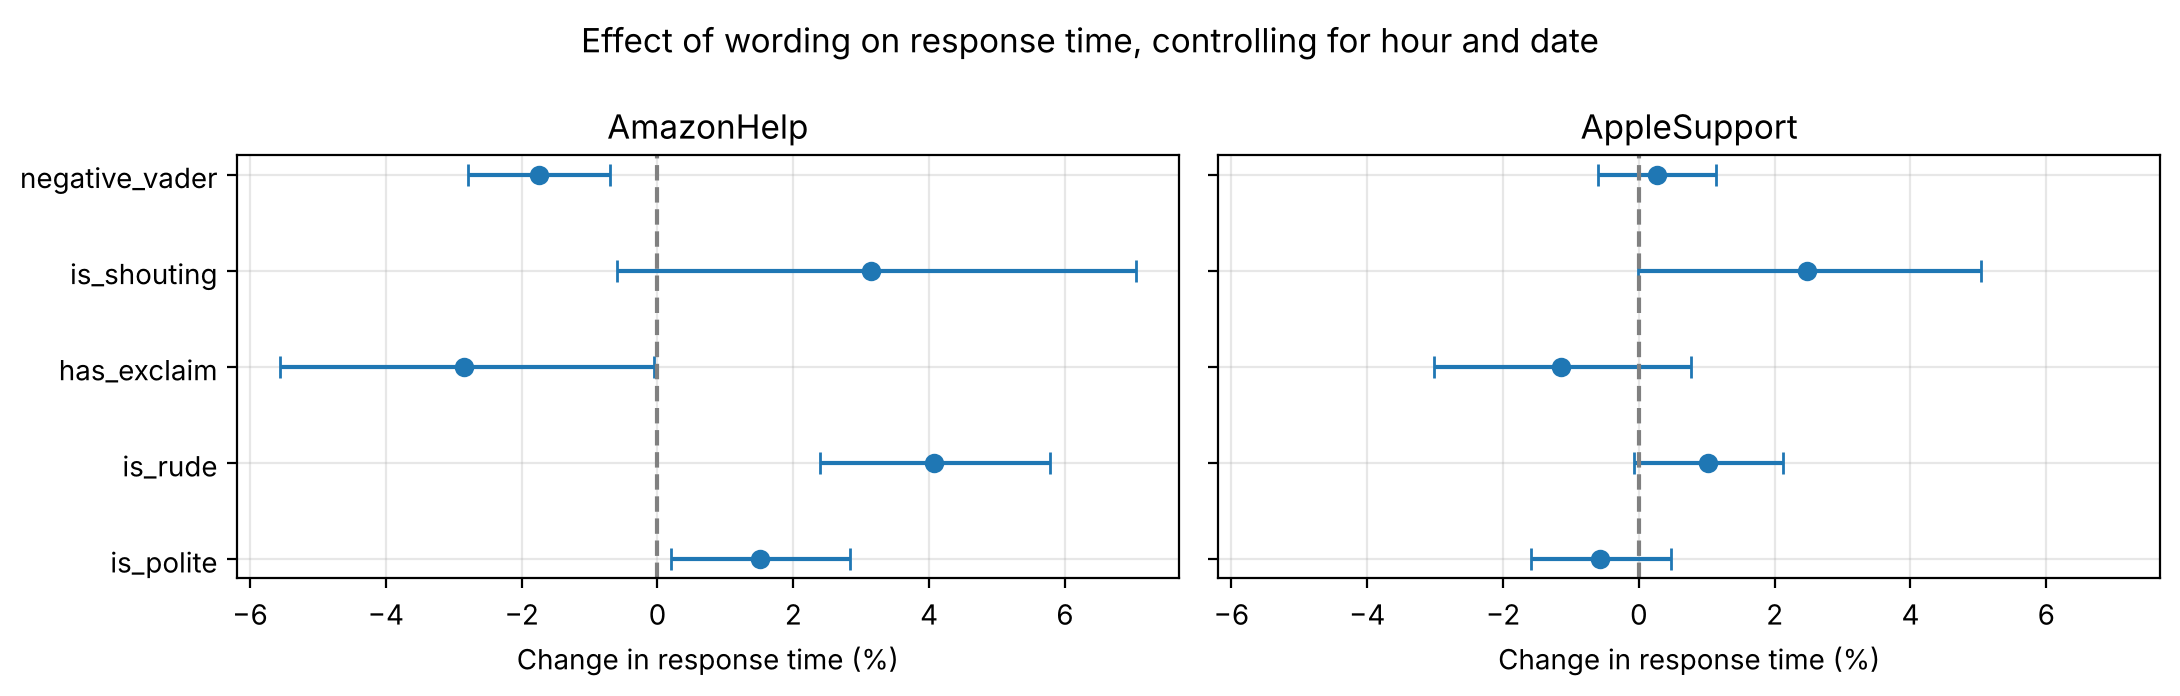

In [ ]:
# Plot the estimated effects with 95% confidence intervals
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True, sharey=True)  # same x-axis so brands are comparable
for ax, (brand, group) in zip(axes, effects.groupby("brand")):
    y = range(len(group))
    ax.errorbar(group["effect_%"], y,
                xerr=[group["effect_%"] - group["ci_low_%"], group["ci_high_%"] - group["effect_%"]],
                fmt="o", capsize=4)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(list(y))
    ax.set_yticklabels(group["feature"])
    ax.set_title(brand)
    ax.set_xlabel("Change in response time (%)")
    ax.grid(alpha=0.3)
plt.suptitle("Effect of wording on response time, controlling for hour and date")
plt.tight_layout()
plt.show()

### 10. Sensitivity Check: Splitting Out "Thanks"

The manual check showed that most wrong polite labels are **sarcastic "thanks"** (*"Thanks for ruining my presents"*), and we could not find a simple rule that detects sarcasm reliably. So instead we ask: **does sarcasm change our conclusion?**

We split the polite words into two groups and put both into the regression:

- `has_thanks`: tweets with *thanks / thx / ty*, where most of the sarcasm is
- `is_polite_other`: tweets with any other polite word (*please, could you, hi, dear, ...*)

We also control for `is_first_tweet` (whether the tweet starts a conversation), because "thanks" often appears in the last tweet of a conversation.

In [ ]:
# Split the polite words: "thanks" words vs all other polite words
thanks_words = [r"thank(?:s|you|u)?", "thx", "ty"]
other_polite_words = [w for w in polite_words if w not in thanks_words]

cases["has_thanks"] = text.str.contains(r"\b(?:" + "|".join(thanks_words) + r")\b", case=False, regex=True)
cases["is_polite_other"] = text.str.contains(r"\b(?:" + "|".join(other_polite_words) + r")\b", case=False, regex=True)

print(cases[["has_thanks", "is_polite_other"]].mean().round(3))
print()
print("Share of tweets that start a conversation:")
print(cases.groupby("has_thanks")["is_first_tweet"].mean().round(3))

has_thanks         0.060
is_polite_other    0.129
dtype: float64

Share of tweets that start a conversation:
has_thanks
False    0.617
True     0.463
Name: is_first_tweet, dtype: float64


In [ ]:
# Same regression as before, with the polite words split and a control for conversation start
features_split = ["is_polite_other", "has_thanks", "is_rude", "has_exclaim", "is_shouting"]
formula_split = "log_minutes ~ " + " + ".join(features_split) + " + is_first_tweet + C(hour) + C(date)"

results = []
for brand, group in cases.groupby("brand"):
    model = smf.ols(formula_split, data=group).fit(cov_type="HC1")
    median_wait = group["response_minutes"].median()
    for f in features_split:
        name = f + "[T.True]"
        low, high = model.conf_int().loc[name]
        effect = np.exp(model.params[name]) - 1
        results.append({
            "brand": brand,
            "feature": f,
            "effect_%": effect * 100,
            "ci_low_%": (np.exp(low) - 1) * 100,
            "ci_high_%": (np.exp(high) - 1) * 100,
            "p_value": model.pvalues[name],
            "approx_minutes": effect * median_wait,   # effect in minutes at the brand's median wait
        })

effects_split = pd.DataFrame(results)
effects_split.round(3)

,brand,feature,effect_%,ci_low_%,ci_high_%,p_value,approx_minutes
0,AmazonHelp,is_polite_other,11.557,9.956,13.181,0.000,1.389
1,AmazonHelp,has_thanks,-15.872,-17.638,-14.069,0.000,-1.907
2,AmazonHelp,is_rude,3.665,2.057,5.299,0.000,0.440
3,AmazonHelp,has_exclaim,-2.049,-4.781,0.761,0.151,-0.246
4,AmazonHelp,is_shouting,3.003,-0.731,6.878,0.116,0.361
5,AppleSupport,is_polite_other,0.844,-0.343,2.046,0.164,0.607
6,AppleSupport,has_thanks,-3.055,-4.654,-1.430,0.000,-2.198
7,AppleSupport,is_rude,0.314,-0.685,1.323,0.540,0.226
8,AppleSupport,has_exclaim,-1.485,-3.353,0.420,0.126,-1.068
9,AppleSupport,is_shouting,1.909,-0.575,4.455,0.133,1.373


Splitting the polite words reveals something the combined label hid. For **AmazonHelp**, the two kinds of polite words move in **opposite directions**: tweets with "thanks" are answered about 16% faster, while tweets with other polite words (*please, could you, ...*) wait about 12% longer. In the combined `is_polite` label these two effects cancel out. For **AppleSupport**, both effects are small (-3% for "thanks" and +1% for other polite words, the latter not significant).

One possible reason (not tested here) is that "please / could you" tweets often ask for something new that needs checking, while many "thanks" tweets close a conversation and only need a short reply. In minutes, all these effects are about 2 minutes or less, much smaller than the posting-time effect for Apple (hundreds of minutes).

### Findings: Wording

- **How common:** 18% of tweets contain polite words, 15% rude words, 4% have "!!" and 2% are shouting. In tone groups: 16% Polite, 13% Rude, 2% Mixed, 69% Neutral.
- **How reliable are the labels?** In the manual check, **96%** of rude labels were correct (48 of 50), but only **69%** of polite labels (34 of 49). Most polite errors are **sarcastic "thanks"** (*"Thanks for ruining my presents"*). Using the Polite tone group (no rude words) raises this to 77%. VADER is fooled by sarcasm too (*"Thanks for nothing"* scores +0.44). So our results about rude wording are more trustworthy than our results about polite wording.
- **At first glance:** AmazonHelp waits are the same for every tone (11.8-13.2 min median). AppleSupport looks slower for rude tweets (94 min) than for neutral (67 min) or polite (75 min) ones, and also for "!!" (+20 min) and shouting (+23 min).
- **But rude tweets are posted at different times.** For Apple, 25.5% of tweets are rude during the iOS 11.1 bug vs 17.4% outside it, and 23% at night vs 18% in the morning. These are exactly the times when Apple is slow anyway.
- **Within the same time of day** (outside the bug), the gap mostly disappears: in the afternoon, polite, neutral and rude tweets wait 31, 31 and 33 minutes.
- **The regression confirms this.** After controlling for the exact hour and date, every wording effect in this main regression is within about **±5%**. For Apple, rude wording changes the wait by +1.0% (95% CI -0.1% to +2.1%, not significant) and polite wording by -0.6% (not significant). For Amazon, rude tweets wait 4% longer (significant, but only about half a minute on a 12-minute wait).
- **Sensitivity check (Section 10).** Because sarcastic "thanks" makes the polite label noisy, we split polite words into "thanks" words and other polite words. For Amazon this reveals two opposite effects that cancelled out in the combined label: "thanks" tweets are answered about 16% faster (about 2 minutes), while "please / could you" tweets wait about 12% longer (about 1.4 minutes). For Apple both are small (-3% and +1%). The rude effect does not change (Amazon +4%, Apple +0.3%, not significant), so sarcasm does not affect our conclusion about rude wording.

## RQ1 Summary

**Answer to RQ1: when a customer posts matters much more than how they write.**

| | Posting time | Wording (after controlling for time) |
|---|---|---|
| **AmazonHelp** | Small effect: 8-19 min median at every hour | Small: rude +4%; "please"-type words +12%; "thanks" -16% (each 2 minutes or less) |
| **AppleSupport** | Large effect: night posts wait about 10x longer than afternoon posts (437 vs 44 min); Friday and Saturday are slower | Tiny: rude +0.3% (not significant), "thanks" -3% |

- Rude tweets *look* slower for Apple (94 vs 67 min), but this is because rude tweets are more common at night and during the iOS 11.1 bug, when Apple is slow anyway. Once we compare tweets posted at the same hour on the same day, rude wording makes almost no difference.
- Polite wording has small effects for Amazon, and the direction depends on the kind of polite words: "thanks" tweets are answered a little faster, "please / could you" tweets a little slower. These effects are at most about 2 minutes.
- For the waiting-time estimate in the Prediction step, **posting hour, weekday and date** are useful inputs; the polite/rude words change the estimate by only a few minutes.

**Limitations**
- We do not know each customer's real time zone; we use US Eastern Time for everyone.
- Word lists cannot read sarcasm or context; polite labels in particular are only about 70-77% correct.
- VADER measures sentiment, not politeness, and is also fooled by sarcasm.
- The regression shows association, not causation: rude tweets may differ in other ways (e.g. harder problems), which we cannot observe.